Exploratory data analysis (EDA) is a crucial component of data science which allows you to understand the basics of what your data looks like and what kinds of questions might be answered. For this task, we are going to clean, sanitise and explore our data. Using the automobile dataset, complete the steps outlined in this notebook by writing code in the cells.

In [1]:
# Import libraries

import numpy as np
import pandas as pd
import seaborn as sns

from datetime import datetime
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# Load the movies dataset
automobiles_df = pd.read_csv('automobile.txt')

### Data Cleansing
#### Clean the data

Identify columns that are redundant or unnecessary. It is always easier to make your decisions based on data which is relevant and concise. Remove the following columns `['normalized-losses', 'symboling']` from the data set as they will not be used in the analysis.

In [3]:
# Code here
automobiles_df.drop('normalized-losses', axis=1, inplace=True)
automobiles_df.head(10)


,symboling,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,audi,gas,std,four,sedan,fwd,front,99.8,176.6,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,audi,gas,std,four,sedan,4wd,front,99.4,176.6,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
5,2,audi,gas,std,two,sedan,fwd,front,99.8,177.3,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250
6,1,audi,gas,std,four,sedan,fwd,front,105.8,192.7,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,17710
7,1,audi,gas,std,four,wagon,fwd,front,105.8,192.7,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,18920
8,1,audi,gas,turbo,four,sedan,fwd,front,105.8,192.7,...,131,mpfi,3.13,3.40,8.3,140,5500,17,20,23875
9,0,audi,gas,turbo,two,hatchback,4wd,front,99.5,178.2,...,131,mpfi,3.13,3.40,7.0,160,5500,16,22,?


In [4]:
automobiles_df.drop('symboling', axis=1, inplace=True)
automobiles_df.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


#### Remove any duplicate rows

Return the number of rows and columns of the automobiles dataframe

In [5]:
# Return the number of rows and columns of the Automobile DataFrame
automobiles_df.shape

(205, 24)

In [6]:
# Remove duplicate rows and persist changes
automobiles_df = automobiles_df.drop_duplicates()
print('Shape after removing duplicates:', automobiles_df.shape)

Shape after removing duplicates: (205, 24)


#### Remove rows with missing data

Some automobiles in the database have missing values which implies that their values have not been recorded or some information is missing. Discard such entries from the dataframe.

In [7]:
# Code here
# Get the number of missing data values per column
missing_values_count = automobiles_df.isnull().sum()

# Look at the number of missing values in the first ten columns
missing_values_count[0:10]

make               0
fuel-type          0
aspiration         0
num-of-doors       0
body-style         0
drive-wheels       0
engine-location    0
wheel-base         0
length             0
width              0
dtype: int64

Removing rows with missing data

In [8]:
# Replace '?' with NaN and remove missing values
automobiles_df = automobiles_df.replace('?', np.nan)
automobiles_df = automobiles_df.dropna()
print('Shape after removing missing values:', automobiles_df.shape)

Shape after removing missing values: (193, 24)


In [9]:
print(automobiles_df.columns.tolist())

['make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']


#### Remove any extra spaces from column names

In [10]:
automobiles_df.columns = automobiles_df.columns.str.strip()

print(automobiles_df.columns.tolist())

['make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']


#### Convert columns that exists

In [11]:
# Convert numeric columns
# Replace '?' with NaN first
automobiles_df = automobiles_df.replace('?', np.nan)

# Convert only numeric columns
numeric_columns = [
    'price',
    'city-mpg',
    'highway-mpg',
    'engine-size',
    'horsepower',
    'peak-rpm',
    'bore',
    'stroke',

]

for col in numeric_columns:
    automobiles_df[col] = pd.to_numeric(automobiles_df[col], errors='coerce')

### Finding Certain Categories
Locate all automobiles in the "hatchback" genre.

In [12]:
# Create a dataframe with all the cars in the "hatchback' category
hatchback_cars = automobiles_df[automobiles_df["body-style"] == "hatchback"]
print(hatchback_cars)


            make fuel-type aspiration num-of-doors body-style drive-wheels  \
2    alfa-romero       gas        std          two  hatchback          rwd   
18     chevrolet       gas        std          two  hatchback          fwd   
19     chevrolet       gas        std          two  hatchback          fwd   
21         dodge       gas        std          two  hatchback          fwd   
22         dodge       gas        std          two  hatchback          fwd   
..           ...       ...        ...          ...        ...          ...   
175       toyota       gas        std         four  hatchback          fwd   
177       toyota       gas        std         four  hatchback          fwd   
178       toyota       gas        std          two  hatchback          rwd   
179       toyota       gas        std          two  hatchback          rwd   
190   volkswagen       gas        std          two  hatchback          fwd   

    engine-location  wheel-base  length  width  ...  engine-siz

### Now onto the exploration

#### Identify relationships between variables (features)

The main goal here is to identify and create relationships that can help you formulate ideas. We have defined questions to help you identify some relationships to explore.

#### Which are the 5 most expensive cars?

How do the most expensive and cheapest cars compare? Exploring the most expensive cars highlights if some moviecars are worth the money spent on them based on their fuel economy (mpg or miles per gallon)

In [13]:
top_5_expensive = automobiles_df.nlargest(5,'price')
print(top_5_expensive[['make','price']])

              make  price
74   mercedes-benz  45400
16             bmw  41315
73   mercedes-benz  40960
128        porsche  37028
17             bmw  36880


#### Which manufacturer builds the most fuel efficient vehicles?

Compare the average mpg for each vehicle manufacture's vehicles and create a bar plot

In [14]:
avg_mpg = automobiles_df.groupby('make')[['city-mpg','highway-mpg']].mean()
print(avg_mpg)

                city-mpg  highway-mpg
make                                 
alfa-romero    20.333333    26.666667
audi           19.333333    24.500000
bmw            19.375000    25.375000
chevrolet      41.000000    46.333333
dodge          28.500000    34.625000
honda          30.384615    35.461538
isuzu          24.000000    29.000000
jaguar         14.333333    18.333333
mazda          27.833333    34.083333
mercedes-benz  18.500000    21.000000
mercury        19.000000    24.000000
mitsubishi     24.923077    31.153846
nissan         27.000000    32.944444
peugot         22.454545    26.636364
plymouth       28.142857    34.142857
porsche        17.500000    25.500000
saab           20.333333    27.333333
subaru         26.333333    30.750000
toyota         27.500000    32.906250
volkswagen     28.583333    34.916667
volvo          21.181818    25.818182


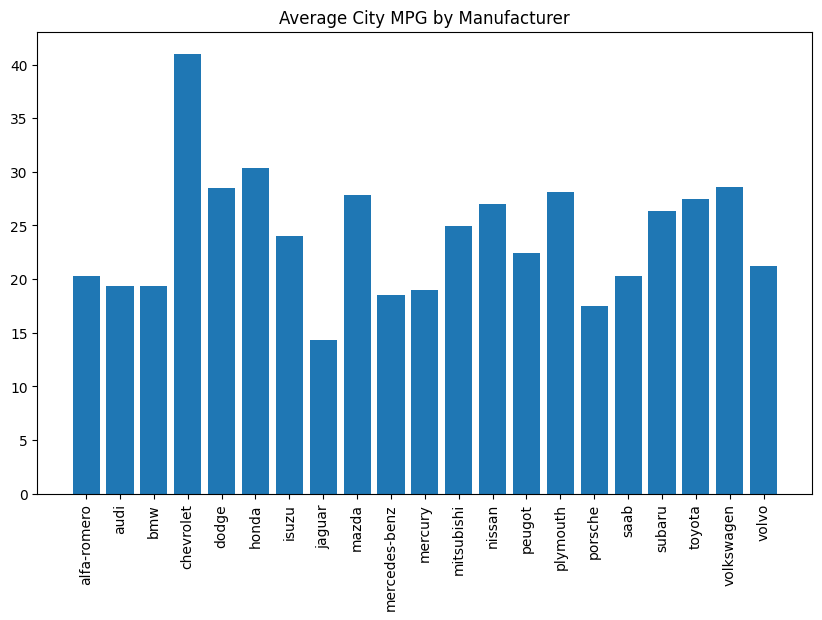

In [15]:
plt.figure(figsize=(10,6))
plt.bar(avg_mpg.index, avg_mpg['city-mpg'])
plt.xticks(rotation=90)
plt.title('Average City MPG by Manufacturer')
plt.show()

Average mpg for each vehicle manufacturers in highway

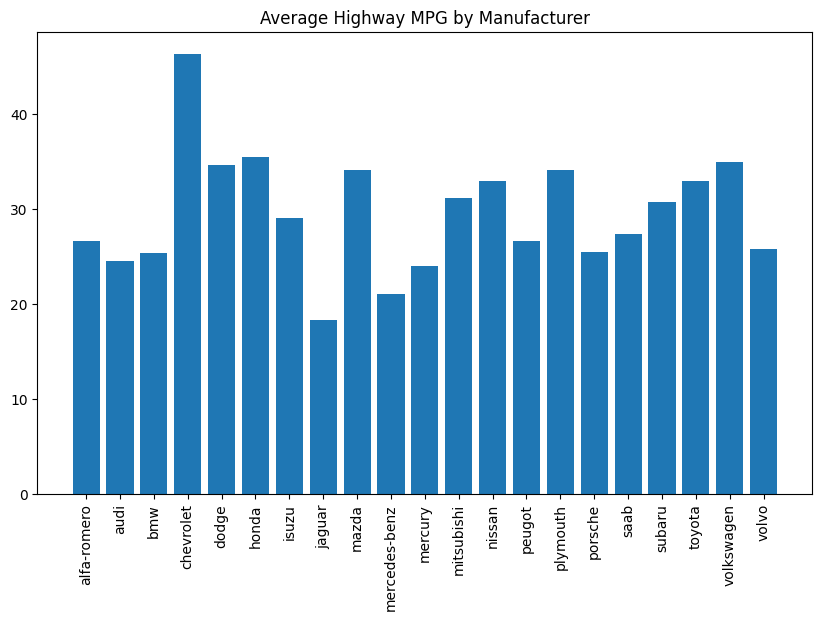

In [16]:
plt.figure(figsize=(10,6))
plt.bar(avg_mpg.index, avg_mpg['highway-mpg'])
plt.xticks(rotation=90)
plt.title('Average Highway MPG by Manufacturer')
plt.show()

#### Which vehicles have the largest engine capacity.
Sort the dataframe based on the engine-size column.

In [17]:
# Code here
automobiles_df.sort_values(by='engine-size', ascending=False).head()


,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
49,jaguar,gas,std,two,sedan,rwd,front,102.0,191.7,70.6,...,326,mpfi,3.54,2.76,11.5,262,5000,13,17,36000
73,mercedes-benz,gas,std,four,sedan,rwd,front,120.9,208.1,71.7,...,308,mpfi,3.80,3.35,8.0,184,4500,14,16,40960
74,mercedes-benz,gas,std,two,hardtop,rwd,front,112.0,199.2,72.0,...,304,mpfi,3.80,3.35,8.0,184,4500,14,16,45400
47,jaguar,gas,std,four,sedan,rwd,front,113.0,199.6,69.6,...,258,mpfi,3.63,4.17,8.1,176,4750,15,19,32250
48,jaguar,gas,std,four,sedan,rwd,front,113.0,199.6,69.6,...,258,mpfi,3.63,4.17,8.1,176,4750,15,19,35550


#### Which vehicle manufacturer has the most car models in the dataset

In [18]:
most_models = automobiles_df['make'].value_counts()
print(most_models)
print('Manufacturer with highest number of models:', most_models.idxmax())

make
toyota           32
nissan           18
honda            13
mitsubishi       13
mazda            12
subaru           12
volkswagen       12
peugot           11
volvo            11
bmw               8
dodge             8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
mercury           1
Name: count, dtype: int64
Manufacturer with highest number of models: toyota


The report was written by Lungelo Ndabambi